# Nigerian Equipment Marketplace Analysis

## Task 2: Exploratory Data Analysis

Part of a three-task project on one dataset: Task 1 collection, **Task 2 exploratory data analysis**, Task 3 visualization.

**Business Question (whole project):** What does the marketplace's listed equipment inventory reveal about category representation, geographic concentration, and advertised price availability, and how can these insights support marketplace planning?

**Objective:** Clean and explore the collected listings, check data quality, and summarize category, location, condition and pricing patterns.

**Input:** `data/equipment_listings_raw.json` from Task 1 (245 listings; 158 equipment listings remain after service listings are removed).

**Output:** `data/nigerian_equipment_marketplace_cleaned.csv` (158 listings), used in Task 3.

**Guiding questions:**
1. Which equipment categories dominate the listings?
2. Where are the listings concentrated geographically?
3. How many listings show a price, and how extreme are the prices?
4. What data-quality issues limit the analysis?

In [1]:
import json
import pandas as pd

with open("data/equipment_listings_raw.json", encoding="utf-8") as f:
    all_listings = json.load(f)

print("Loaded", len(all_listings), "listings")

Loaded 245 listings



### Converting Collected Records into a DataFrame


### Initial Data Inspection

In [2]:

df = pd.DataFrame(all_listings)

print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

df.head()


Dataset shape: (245, 18)
Column names:
['id', 'title', 'category', 'subcategory', 'location', 'condition', 'availability', 'minimumLease', 'dailyRate', 'monthlyRate', 'annualRate', 'salePrice', 'createdAt', 'updatedAt', 'listingType', 'verificationStatus', 'isFeatured', 'views']


,id,title,category,subcategory,location,condition,availability,minimumLease,dailyRate,monthlyRate,annualRate,salePrice,createdAt,updatedAt,listingType,verificationStatus,isFeatured,views
0,413,Wuling Bingo Plus,Transport & Logistic,Electric Vehicles,"Lagos, Nigeria",Brand New,Available now,1 Months,"69,100","12,600,000","25,200,000","42,000,000",Mon Jul 06 2026 14:21:33 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:24:31 GMT+0000 (Coordinated...,equipment,,true,26710
1,412,Mobile Toilet,Others,Special Requests,"Aboru Iyanapaja, Lagos, Nigeria",Used - Excellent,Available now,,250.00,"40,500.00","74,825.00","50,000",Thu Jun 18 2026 09:50:39 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:39:35 GMT+0000 (Coordinated...,equipment,,false,23269
2,411,Scissors lift,Construction & Infrastruture,Excavators,"Lagos, Nigeria",Used - Excellent,Available now,,"80,000","12,960,000.00","23,944,000.00",,Mon Jun 15 2026 10:28:44 GMT+0000 (Coordinated...,Sat Oct 17 2026 05:26:25 GMT+0000 (Coordinated...,equipment,,false,31551
3,410,"70, Tones Crane",Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,"400,000","64,800,000.00","119,720,000.00",,Mon Jun 15 2026 10:26:45 GMT+0000 (Coordinated...,Sat Oct 17 2026 02:22:09 GMT+0000 (Coordinated...,equipment,,false,461
4,409,Swap buggies,Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,"290,000","46,980,000.00","86,797,000.00",,Mon Jun 15 2026 10:24:37 GMT+0000 (Coordinated...,Fri Oct 16 2026 15:02:32 GMT+0000 (Coordinated...,equipment,,false,311



### Understanding Listing Types


In [3]:
print(df["listingType"].value_counts(dropna=False))

listingType
equipment    158
service       87
Name: count, dtype: int64



### Initial Data Quality Assessment


In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)

print(missing_values[missing_values > 0])

monthlyRate     87
condition       87
annualRate      87
availability    87
minimumLease    87
salePrice       81
dtype: int64


In [5]:
columns_to_check = [
    
    "title",
    "category",
    "subcategory",
    "location",
    "condition",
    "dailyRate",
    "monthlyRate",
    "annualRate",
    "salePrice",
    "views",
    "createdAt"
]

print(df[columns_to_check].head(10).to_string(index=False))

            title                     category             subcategory                        location        condition dailyRate   monthlyRate     annualRate  salePrice views                                                      createdAt
Wuling Bingo Plus         Transport & Logistic       Electric Vehicles                  Lagos, Nigeria        Brand New    69,100    12,600,000     25,200,000 42,000,000 26710 Mon Jul 06 2026 14:21:33 GMT+0000 (Coordinated Universal Time)
   Mobile Toilet                        Others        Special Requests Aboru Iyanapaja, Lagos, Nigeria Used - Excellent    250.00     40,500.00      74,825.00     50,000 23269 Thu Jun 18 2026 09:50:39 GMT+0000 (Coordinated Universal Time)
    Scissors lift Construction & Infrastruture              Excavators                  Lagos, Nigeria Used - Excellent    80,000 12,960,000.00  23,944,000.00            31551 Mon Jun 15 2026 10:28:44 GMT+0000 (Coordinated Universal Time)
 70, Tones Crane  Construction & Infrastrutu

### Selecting Equipment Listings and Analysis Fields

In [6]:

# Keep only equipment listings
df_equipment = df[df["listingType"] == "equipment"].copy()

print("Equipment dataset shape:", df_equipment.shape)
print("Unique listing IDs:", df_equipment["id"].nunique())
print("Duplicate listing IDs:", df_equipment["id"].duplicated().sum())

df_equipment[["title", "category", "location", "dailyRate", "salePrice"]].head()


Equipment dataset shape: (158, 18)
Unique listing IDs: 158
Duplicate listing IDs: 0


,title,category,location,dailyRate,salePrice
0,Wuling Bingo Plus,Transport & Logistic,"Lagos, Nigeria","69,100","42,000,000"
1,Mobile Toilet,Others,"Aboru Iyanapaja, Lagos, Nigeria",250.00,"50,000"
2,Scissors lift,Construction & Infrastruture,"Lagos, Nigeria","80,000",
3,"70, Tones Crane",Construction & Infrastruture,"Lagos, Nigeria","400,000",
4,Swap buggies,Construction & Infrastruture,"Lagos, Nigeria","290,000",


In [7]:

equipment_missing = (
    df_equipment.isnull()
    .sum()
    .sort_values(ascending=False)
)

print(equipment_missing[equipment_missing > 0])


Series([], dtype: int64)


In [8]:

# Select fields relevant to the analysis
columns_to_keep = [
    "id",
    "title",
    "category",
    "subcategory",
    "location",
    "condition",
    "availability",
    "minimumLease",
    "dailyRate",
    "monthlyRate",
    "annualRate",
    "salePrice",
    "createdAt",
    "updatedAt",
    "listingType",
    "verificationStatus",
    "isFeatured",
    "views"
]

df_analysis = df_equipment[columns_to_keep].copy()

# Clean the price fields and convert them to numbers
price_columns = [
    "dailyRate",
    "monthlyRate",
    "annualRate",
    "salePrice"
]

for col in price_columns:
    cleaned_prices = (
        df_analysis[col]
        .astype("string")
        .str.replace(r"[₦,]", "", regex=True)
        .str.replace(r"(?i)ngn", "", regex=True)
        .str.replace(r"^\s*N\s*", "", regex=True)
        .str.strip()
    )

    df_analysis[col] = pd.to_numeric(
        cleaned_prices,
        errors="coerce"
    )

print("Analysis dataset shape:", df_analysis.shape)
print("\nData types:")
print(df_analysis[price_columns].dtypes)

df_analysis.head()


Analysis dataset shape: (158, 18)

Data types:
dailyRate      Float64
monthlyRate    Float64
annualRate     Float64
salePrice      Float64
dtype: object


,id,title,category,subcategory,location,condition,availability,minimumLease,dailyRate,monthlyRate,annualRate,salePrice,createdAt,updatedAt,listingType,verificationStatus,isFeatured,views
0,413,Wuling Bingo Plus,Transport & Logistic,Electric Vehicles,"Lagos, Nigeria",Brand New,Available now,1 Months,69100.0,12600000.0,25200000.0,42000000.0,Mon Jul 06 2026 14:21:33 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:24:31 GMT+0000 (Coordinated...,equipment,,true,26710
1,412,Mobile Toilet,Others,Special Requests,"Aboru Iyanapaja, Lagos, Nigeria",Used - Excellent,Available now,,250.0,40500.0,74825.0,50000.0,Thu Jun 18 2026 09:50:39 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:39:35 GMT+0000 (Coordinated...,equipment,,false,23269
2,411,Scissors lift,Construction & Infrastruture,Excavators,"Lagos, Nigeria",Used - Excellent,Available now,,80000.0,12960000.0,23944000.0,<NA>,Mon Jun 15 2026 10:28:44 GMT+0000 (Coordinated...,Sat Oct 17 2026 05:26:25 GMT+0000 (Coordinated...,equipment,,false,31551
3,410,"70, Tones Crane",Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,400000.0,64800000.0,119720000.0,<NA>,Mon Jun 15 2026 10:26:45 GMT+0000 (Coordinated...,Sat Oct 17 2026 02:22:09 GMT+0000 (Coordinated...,equipment,,false,461
4,409,Swap buggies,Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,290000.0,46980000.0,86797000.0,<NA>,Mon Jun 15 2026 10:24:37 GMT+0000 (Coordinated...,Fri Oct 16 2026 15:02:32 GMT+0000 (Coordinated...,equipment,,false,311


In [9]:

# Check listing types in the analysis dataset
print("Listing type counts:")
print(df_analysis["listingType"].value_counts(dropna=False))

# Check fields that should help describe each listing
check_columns = [
    "title",
    "category",
    "location",
    "listingType",
    "createdAt",
    "dailyRate",
    "monthlyRate",
    "annualRate",
    "salePrice"
]

print("\nMissing values before blank-string cleanup:")
print(df_analysis[check_columns].isna().sum())

# Check for empty or whitespace-only text
print("\nBlank text values:")
for col in check_columns:
    if df_analysis[col].dtype == "object" or str(df_analysis[col].dtype) == "string":
        blank_count = (
            df_analysis[col]
            .astype("string")
            .str.strip()
            .eq("")
            .sum()
        )
        if blank_count > 0:
            print(f"{col}: {blank_count}")


Listing type counts:
listingType
equipment    158
Name: count, dtype: int64

Missing values before blank-string cleanup:
title            0
category         0
location         0
listingType      0
createdAt        0
dailyRate      143
monthlyRate    144
annualRate     144
salePrice       39
dtype: int64

Blank text values:


In [10]:
print(
    df_analysis.loc[
        df_analysis["title"].str.contains("Swap buggies", case=False, na=False),
        ["id", "title", "listingType", "dailyRate", "monthlyRate", "annualRate", "salePrice"]
    ].to_string(index=False)
)

 id        title listingType  dailyRate  monthlyRate  annualRate  salePrice
409 Swap buggies   equipment   290000.0   46980000.0  86797000.0       <NA>


### Checking Price Data

In [11]:

# Count missing values in each price column
price_columns = ["dailyRate", "monthlyRate", "annualRate", "salePrice"]

print("Missing price values:")
print(df_analysis[price_columns].isna().sum())

# Count listings that have at least one price
print("\nListings with at least one available price:")
print(df_analysis[price_columns].notna().any(axis=1).sum())

# Count listings with no price in any of the four columns
print("\nListings with no available price:")
print(df_analysis[price_columns].isna().all(axis=1).sum())


Missing price values:
dailyRate      143
monthlyRate    144
annualRate     144
salePrice       39
dtype: int64

Listings with at least one available price:
129

Listings with no available price:
29


In [12]:

# Identify equipment listings with no recorded price
no_price_mask = df_analysis[price_columns].isna().all(axis=1)

df_no_price = df_analysis.loc[
    no_price_mask,
    ["id", "title", "category", "subcategory", "location", "condition"]
].copy()

print("Listings without any recorded price:", len(df_no_price))
display(df_no_price.head(15))


Listings without any recorded price: 29


,id,title,category,subcategory,location,condition
14,393,30-tons capacity Howo Truck,Transport & Logistic,Heavy Duty Trucks,"Abuja, Abuja, Nigeria",Used - Excellent
28,379,Fullrange and Sub-woofer speakers,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent
72,327,Black Toyota Hilux Police Truck.,Transport & Logistic,Pickup Trucks,"Wuse 2, Abuja, Nigeria",Used - Excellent
73,326,Toyota Land Cruiser Prado,Transport & Logistic,SUVs & Utility Vehicles,"Wuse 2, Abuja, Nigeria",Used - Excellent
74,325,Ford Ranger,Transport & Logistic,Pickup Trucks,"Wuse 2, Abuja, Nigeria",Used - Excellent
75,324,Toyota Hilux,Transport & Logistic,Pickup Trucks,"Wuse 2, Abuja, Nigeria",Used - Excellent
76,323,Stage Deck,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent
77,322,Fullrange and Sub-woofer speakers,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent
78,321,Toyota Hilux Pilot Van,Transport & Logistic,Dump Trucks,"Wuse 2, Abuja, Nigeria",Used - Excellent
79,320,Monitor speakers,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent


In [13]:

# Identify which pricing fields are available for each listing
df_analysis["has_sale_price"] = df_analysis["salePrice"].notna()

df_analysis["has_daily_rate"] = df_analysis["dailyRate"].notna()

df_analysis["has_monthly_rate"] = df_analysis["monthlyRate"].notna()

df_analysis["has_annual_rate"] = df_analysis["annualRate"].notna()

# Summarise the availability of each pricing field
pricing_summary = pd.DataFrame({
    "Pricing Field": [
        "Sale price",
        "Daily rental rate",
        "Monthly rental rate",
        "Annual rental rate"
    ],
    "Listings with price": [
        df_analysis["has_sale_price"].sum(),
        df_analysis["has_daily_rate"].sum(),
        df_analysis["has_monthly_rate"].sum(),
        df_analysis["has_annual_rate"].sum()
    ]
})

pricing_summary["Listings without price"] = (
    len(df_analysis) - pricing_summary["Listings with price"]
)

display(pricing_summary)


,Pricing Field,Listings with price,Listings without price
0,Sale price,119,39
1,Daily rental rate,15,143
2,Monthly rental rate,14,144
3,Annual rental rate,14,144


## Visual Exploration

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs("eda_charts", exist_ok=True)

GREEN = "#0c9103"
GREEN_LIGHT = "#b3dcaf"
GREY = "#555555"

### EDA Chart 1: Missing Values by Field

verificationStatus    100.0
monthlyRate            91.1
annualRate             91.1
dailyRate              90.5
minimumLease           88.0
salePrice              24.7
subcategory             2.5


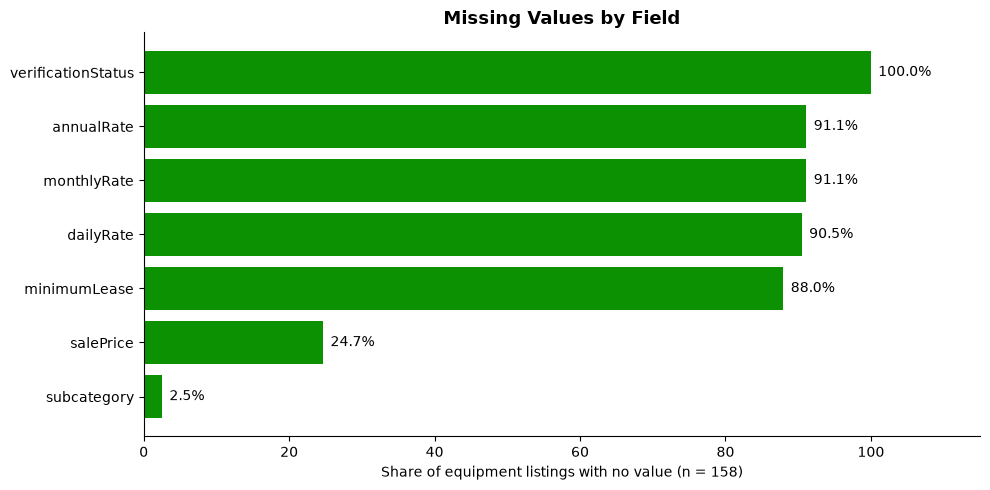

In [15]:
total = len(df_analysis)

# Count empty or whitespace-only text as missing too
df_checked = df_analysis.replace(r"^\s*$", np.nan, regex=True)

missing_pct = df_checked.isna().mean() * 100
missing_pct = missing_pct[missing_pct > 0].sort_values()

print(missing_pct.round(1).sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_pct.index, missing_pct.values, color=GREEN)

for bar in bars:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

ax.set_title("Missing Values by Field", fontsize=13, weight="bold")
ax.set_xlabel(f"Share of equipment listings with no value (n = {total})")
ax.set_ylabel("")
ax.set_xlim(0, 115)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/01_missing_values.png", dpi=200)
plt.show()

**Insight:** The price fields are the main data gap among the 158 equipment listings. Rental rates are missing for about nine in ten listings (daily 90.5%, monthly and annual 91.1% each), and the sale price is missing for 24.7% (39 listings). These gaps reflect what sellers chose to advertise, not data errors: most listings show a sale price or rental rates, rarely both. 29 listings (18.4%) show no price in any of the four fields. Two other fields are almost or completely empty: `verificationStatus` is blank for every listing (100%), so it cannot separate verified from unverified listings, and `minimumLease` is blank for 88.0%, so lease terms cannot be analysed reliably. Only 4 listings (2.5%) lack a subcategory, while category, location and condition are complete. The analysis therefore relies on the complete fields and covers only listings that disclose prices: 119 with a sale price and 14 or 15 with rental rates.

### Duplicate Checks

In [16]:

# Check duplicate listing IDs
print("Duplicate listing IDs:", df_analysis["id"].duplicated().sum())

# Check duplicate titles
print("Duplicate listing titles:", df_analysis["title"].duplicated().sum())

# Display repeated titles for manual inspection
duplicate_titles = df_analysis[
    df_analysis["title"].duplicated(keep=False)
].sort_values("title")

print("\nRepeated listing titles:")
display(duplicate_titles[["id", "title", "category", "location", "salePrice"]])


Duplicate listing IDs: 0
Duplicate listing titles: 4

Repeated listing titles:


,id,title,category,location,salePrice
188,104,Caterpilla Escavator 325 Bl,Agriculture & Mining,"Ibeju, Lagos, Nigeria",150000000.0
189,105,Caterpilla Escavator 325 Bl,Agriculture & Mining,"Ibeju, Lagos, Nigeria",150000000.0
170,136,Server HP ProLiant DL 48GB Intel Xeon 1T,Office & ICT,"Ikeja, Lagos, Nigeria",600000.0
171,135,Server HP ProLiant DL 48GB Intel Xeon 1T,Office & ICT,"Ikeja, Lagos, Nigeria",600000.0
85,314,Yamaha Audio mixer,Others,"Abuja, Abuja, Nigeria",<NA>
86,313,Yamaha Audio mixer,Others,"Abuja, Abuja, Nigeria",<NA>
225,61,ZOOMLION ZE215GE SWAMP BUGGY,Construction & Infrastruture,"ABUJA, FCT, Nigeria",<NA>
231,55,ZOOMLION ZE215GE SWAMP BUGGY,Construction & Infrastruture,"ABUJA, FCT, Nigeria",<NA>


In [17]:

# Compare all rows with repeated titles
duplicate_titles = df_analysis[
    df_analysis["title"].duplicated(keep=False)
].sort_values(["title", "id"])

comparison_columns = [
    "id", "title", "category", "subcategory", "location",
    "condition", "dailyRate", "monthlyRate", "annualRate",
    "salePrice", "createdAt", "updatedAt"
]

display(duplicate_titles[comparison_columns])


,id,title,category,subcategory,location,condition,dailyRate,monthlyRate,annualRate,salePrice,createdAt,updatedAt
188,104,Caterpilla Escavator 325 Bl,Agriculture & Mining,Excavators,"Ibeju, Lagos, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,150000000.0,Wed May 06 2026 12:43:05 GMT+0000 (Coordinated...,Sat Oct 17 2026 05:11:54 GMT+0000 (Coordinated...
189,105,Caterpilla Escavator 325 Bl,Agriculture & Mining,Excavators,"Ibeju, Lagos, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,150000000.0,Wed May 06 2026 12:43:05 GMT+0000 (Coordinated...,Fri Oct 16 2026 09:21:53 GMT+0000 (Coordinated...
171,135,Server HP ProLiant DL 48GB Intel Xeon 1T,Office & ICT,Servers,"Ikeja, Lagos, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,600000.0,Thu May 07 2026 10:09:32 GMT+0000 (Coordinated...,Fri Oct 16 2026 19:58:44 GMT+0000 (Coordinated...
170,136,Server HP ProLiant DL 48GB Intel Xeon 1T,Office & ICT,Servers,"Ikeja, Lagos, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,600000.0,Thu May 07 2026 10:09:34 GMT+0000 (Coordinated...,Sat Oct 17 2026 03:59:18 GMT+0000 (Coordinated...
86,313,Yamaha Audio mixer,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,<NA>,Tue May 19 2026 14:31:17 GMT+0000 (Coordinated...,Wed Oct 14 2026 13:26:42 GMT+0000 (Coordinated...
85,314,Yamaha Audio mixer,Others,Special Requests,"Abuja, Abuja, Nigeria",Used - Excellent,<NA>,<NA>,<NA>,<NA>,Tue May 19 2026 14:31:18 GMT+0000 (Coordinated...,Sat Oct 17 2026 01:16:37 GMT+0000 (Coordinated...
231,55,ZOOMLION ZE215GE SWAMP BUGGY,Construction & Infrastruture,Excavators,"ABUJA, FCT, Nigeria",Brand New,<NA>,<NA>,<NA>,<NA>,Tue May 05 2026 10:49:46 GMT+0000 (Coordinated...,Mon Jun 01 2026 03:18:58 GMT+0000 (Coordinated...
225,61,ZOOMLION ZE215GE SWAMP BUGGY,Construction & Infrastruture,Excavators,"ABUJA, FCT, Nigeria",Brand New,<NA>,<NA>,<NA>,<NA>,Tue May 05 2026 11:07:42 GMT+0000 (Coordinated...,Tue May 26 2026 05:21:50 GMT+0000 (Coordinated...


### Category, Condition and Location

In [18]:

# Count equipment listings by category
category_summary = (
    df_analysis["category"]
    .value_counts()
    .reset_index()
)

category_summary.columns = ["Category", "Number of Listings"]

# Calculate each category's share of all equipment listings
category_summary["Percentage"] = (
    category_summary["Number of Listings"] / len(df_analysis) * 100
).round(2)

display(category_summary)


,Category,Number of Listings,Percentage
0,Transport & Logistic,32,20.25
1,Construction & Infrastruture,26,16.46
2,Agriculture & Mining,21,13.29
3,Energy & Power,16,10.13
4,Manufacturing & Industrial,13,8.23
5,Others,12,7.59
6,Telecom & Communication,10,6.33
7,Office & ICT,9,5.70
8,Maritime & Shipping,6,3.80
9,HealthCare & Fitness,5,3.16


In [19]:

# Count listings by equipment condition
condition_summary = (
    df_analysis["condition"]
    .value_counts(dropna=False)
    .reset_index()
)

condition_summary.columns = ["Condition", "Number of Listings"]

condition_summary["Percentage"] = (
    condition_summary["Number of Listings"] / len(df_analysis) * 100
).round(2)

display(condition_summary)


,Condition,Number of Listings,Percentage
0,Used - Excellent,78,49.37
1,Brand New,73,46.20
2,Used - Good,7,4.43


In [20]:

# Count listings by recorded location
location_summary = (
    df_analysis["location"]
    .value_counts(dropna=False)
    .reset_index()
)

location_summary.columns = ["Location", "Number of Listings"]

location_summary["Percentage"] = (
    location_summary["Number of Listings"] / len(df_analysis) * 100
).round(2)

print("Number of distinct recorded locations:", df_analysis["location"].nunique())

display(location_summary.head(15))


Number of distinct recorded locations: 66


,Location,Number of Listings,Percentage
0,"ABUJA, FCT, Nigeria",19,12.03
1,"Lagos, Nigeria",14,8.86
2,"Abuja, Abuja, Nigeria",13,8.23
3,"Ikeja, Lagos, Nigeria",10,6.33
4,"Amuwo-Odofin, Lagos, Nigeria",9,5.70
5,"Ojo, Lagos, Nigeria",8,5.06
6,"Wuse 2, Abuja, Nigeria",5,3.16
7,"Lagos Island, Lagos, Nigeria",4,2.53
8,"Eko, Lagos, Nigeria",4,2.53
9,"Lagos Island (Eko), Lagos, Nigeria",3,1.90


In [21]:

# Preserve the original location values
df_analysis["location_original"] = df_analysis["location"]

# Clean extra spaces and standardize capitalization
df_analysis["location_clean"] = (
    df_analysis["location"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# Compare the number of unique location values before and after cleaning
print("Unique original locations:", df_analysis["location_original"].nunique())
print("Unique cleaned locations:", df_analysis["location_clean"].nunique())

# Inspect the most common cleaned locations
display(
    df_analysis["location_clean"]
    .value_counts()
    .head(15)
    .rename_axis("Location")
    .reset_index(name="Number of Listings")
)


Unique original locations: 66
Unique cleaned locations: 58


,Location,Number of Listings
0,"Abuja, Fct, Nigeria",20
1,"Lagos, Nigeria",14
2,"Abuja, Abuja, Nigeria",13
3,"Ikeja, Lagos, Nigeria",11
4,"Amuwo-Odofin, Lagos, Nigeria",9
5,"Ojo, Lagos, Nigeria",8
6,"Lagos Island, Lagos, Nigeria",6
7,"Wuse 2, Abuja, Nigeria",5
8,"Lekki, Lagos, Nigeria",4
9,"Eko, Lagos, Nigeria",4


In [22]:

# Create a broad region field without changing the original locations
def assign_region(location):
    location = str(location).strip().lower()

    if "lagos" in location:
        return "Lagos"
    elif "abuja" in location or "fct" in location:
        return "Abuja / FCT"
    elif "ibadan" in location or "oyo" in location:
        return "Oyo"
    elif "port harcourt" in location or "rivers" in location:
        return "Rivers"
    else:
        return "Other / Review"

df_analysis["region"] = df_analysis["location_clean"].apply(assign_region)

# Summarize listings by broad region
region_summary = (
    df_analysis["region"]
    .value_counts()
    .reset_index()
)

region_summary.columns = ["Region", "Number of Listings"]

region_summary["Percentage"] = (
    region_summary["Number of Listings"] / len(df_analysis) * 100
).round(2)

display(region_summary)


,Region,Number of Listings,Percentage
0,Lagos,84,53.16
1,Abuja / FCT,65,41.14
2,Other / Review,4,2.53
3,Rivers,3,1.90
4,Oyo,2,1.27


In [23]:

# Inspect locations not assigned to a recognized region
other_locations = (
    df_analysis.loc[
        df_analysis["region"] == "Other / Review",
        ["title", "location_original", "location_clean", "region"]
    ]
    .sort_values("location_clean")
)

display(other_locations)


,title,location_original,location_clean,region
183,500watts Itel Power Tank Solar Generator Comes...,"Edo, Benin City, Nigeria","Edo, Benin City, Nigeria",Other / Review
202,Fairly Used Mikano Diesel Generator 40kva List...,"Enugu, Enugu, Nigeria","Enugu, Enugu, Nigeria",Other / Review
194,Combine Harvesters,"Kaduna, Kaduna, Nigeria","Kaduna, Kaduna, Nigeria",Other / Review
182,Colasolar 1200w - 3kwh Ultra-Long Backup Power...,"Kwara, Ilorin South, Nigeria","Kwara, Ilorin South, Nigeria",Other / Review


In [24]:

def assign_region(location):
    location = str(location).strip().lower()

    if "lagos" in location:
        return "Lagos"
    elif "abuja" in location or "fct" in location:
        return "Abuja / FCT"
    elif "port harcourt" in location or "rivers" in location:
        return "Rivers"
    elif "ibadan" in location or "oyo" in location:
        return "Oyo"
    elif "benin city" in location or "edo" in location:
        return "Edo"
    elif "enugu" in location:
        return "Enugu"
    elif "kaduna" in location:
        return "Kaduna"
    elif "ilorin" in location or "kwara" in location:
        return "Kwara"
    else:
        return "Other / Review"

df_analysis["region"] = df_analysis["location_clean"].apply(assign_region)

region_summary = (
    df_analysis["region"]
    .value_counts()
    .rename_axis("Region")
    .reset_index(name="Number of Listings")
)

region_summary["Percentage"] = (
    region_summary["Number of Listings"] / len(df_analysis) * 100
).round(2)

display(region_summary)


,Region,Number of Listings,Percentage
0,Lagos,84,53.16
1,Abuja / FCT,65,41.14
2,Rivers,3,1.90
3,Oyo,2,1.27
4,Kwara,1,0.63
5,Edo,1,0.63
6,Kaduna,1,0.63
7,Enugu,1,0.63


### Sale Price Analysis

In [25]:
sale_price_summary = df_analysis["salePrice"].describe()

display(sale_price_summary)

count              119.0
mean     30242195.369748
std      56557881.502468
min              10000.0
25%             560000.0
50%            6000000.0
75%           42500000.0
max          392450000.0
Name: salePrice, dtype: Float64

In [26]:

# Select listings with a recorded sale price
sale_prices = df_analysis["salePrice"].dropna()

# Calculate the first and third quartiles
Q1 = sale_prices.quantile(0.25)
Q3 = sale_prices.quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

# Identify potential outliers
potential_outliers = df_analysis[
    df_analysis["salePrice"].notna()
    & (
        (df_analysis["salePrice"] < lower_bound)
        | (df_analysis["salePrice"] > upper_bound)
    )
]

print("Potential outlier listings:", len(potential_outliers))

display(
    potential_outliers[
        ["title", "category", "location", "salePrice"]
    ].sort_values("salePrice", ascending=False)
)


Q1: 560000.0
Q3: 42500000.0
IQR: 41940000.0
Lower boundary: -62350000.0
Upper boundary: 105410000.0
Potential outlier listings: 6


,title,category,location,salePrice
191,Brand New Sany Escavator Sy500h -50 Tons,Agriculture & Mining,"Amuwo-Odofin, Lagos, Nigeria",392450000.0
206,Hylas 54 Sail-Boat Cruise Yatch,Maritime & Shipping,"Lagos, Nigeria",337500000.0
189,Caterpilla Escavator 325 Bl,Agriculture & Mining,"Ibeju, Lagos, Nigeria",150000000.0
188,Caterpilla Escavator 325 Bl,Agriculture & Mining,"Ibeju, Lagos, Nigeria",150000000.0
185,Sany Sy215c Excavator,Agriculture & Mining,"Gwarinpa, Abuja, FCT, Nigeria",135000000.0
190,Caterpillar Escavator Bl 320,Agriculture & Mining,"Dei-Dei, Abuja, Nigeria",130000000.0


In [27]:

df_analysis["sale_price_status"] = "No Sale Price"

priced_mask = df_analysis["salePrice"].notna()

outlier_mask = (
    (df_analysis["salePrice"] < lower_bound)
    | (df_analysis["salePrice"] > upper_bound)
)

df_analysis.loc[priced_mask, "sale_price_status"] = "Within IQR Range"

df_analysis.loc[
    priced_mask & outlier_mask,
    "sale_price_status"
] = "Potential Outlier"

print(df_analysis["sale_price_status"].value_counts())

display(
    df_analysis[
        ["title", "salePrice", "sale_price_status"]
    ].sort_values("salePrice", ascending=False).head(10)
)


sale_price_status
Within IQR Range     113
No Sale Price         39
Potential Outlier      6
Name: count, dtype: int64


,title,salePrice,sale_price_status
191,Brand New Sany Escavator Sy500h -50 Tons,392450000.0,Potential Outlier
206,Hylas 54 Sail-Boat Cruise Yatch,337500000.0,Potential Outlier
189,Caterpilla Escavator 325 Bl,150000000.0,Potential Outlier
188,Caterpilla Escavator 325 Bl,150000000.0,Potential Outlier
185,Sany Sy215c Excavator,135000000.0,Potential Outlier
190,Caterpillar Escavator Bl 320,130000000.0,Potential Outlier
177,Hengwang Core Drilling Rig Hw 350l,105000000.0,Within IQR Range
181,Zgyx420b Wagon Drill - Heavy-Duty Hydraulic Ro...,104000000.0,Within IQR Range
178,Kaishan Blast Rock Hole Wagon Crawler Rig With...,100000000.0,Within IQR Range
241,LIUGONG GRADER,95000000.0,Within IQR Range


In [28]:

# All listings with a recorded sale price
all_sale_prices = df_analysis["salePrice"].dropna()

# Listings with sale prices that are not flagged as potential outliers
sale_prices_without_outliers = df_analysis.loc[
    df_analysis["sale_price_status"] == "Within IQR Range",
    "salePrice"
]

comparison = pd.DataFrame({
    "Measure": ["Number of Listings", "Mean Sale Price", "Median Sale Price", "Minimum", "Maximum"],
    "With Potential Outliers": [
        all_sale_prices.count(),
        all_sale_prices.mean(),
        all_sale_prices.median(),
        all_sale_prices.min(),
        all_sale_prices.max()
    ],
    "Without Potential Outliers": [
        sale_prices_without_outliers.count(),
        sale_prices_without_outliers.mean(),
        sale_prices_without_outliers.median(),
        sale_prices_without_outliers.min(),
        sale_prices_without_outliers.max()
    ]
})

display(comparison)


,Measure,With Potential Outliers,Without Potential Outliers
0,Number of Listings,1.190000e+02,1.130000e+02
1,Mean Sale Price,3.024220e+07,2.038824e+07
2,Median Sale Price,6.000000e+06,5.000000e+06
3,Minimum,1.000000e+04,1.000000e+04
4,Maximum,3.924500e+08,1.050000e+08


### EDA Chart 2: Sale Price Outliers

Q1: 560,000 | Median: 6,000,000 | Q3: 42,500,000 | Upper fence: 105,410,000
Listings above the upper fence: 6
Flagged as potential outliers earlier: 6


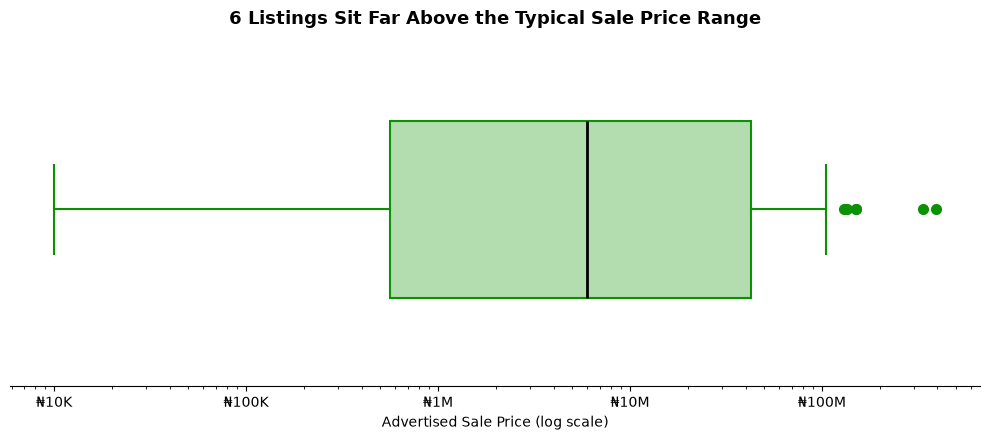

In [29]:
prices = df_analysis["salePrice"].dropna()

q1, median, q3 = prices.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

n_above = int((prices > upper_fence).sum())
n_flagged = int((df_analysis["sale_price_status"] == "Potential Outlier").sum())

print(f"Q1: {q1:,.0f} | Median: {median:,.0f} | Q3: {q3:,.0f} | Upper fence: {upper_fence:,.0f}")
print("Listings above the upper fence:", n_above)
print("Flagged as potential outliers earlier:", n_flagged)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(
    prices, orientation="horizontal", widths=0.5, patch_artist=True,
    boxprops=dict(facecolor=GREEN_LIGHT, edgecolor=GREEN, linewidth=1.5),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color=GREEN, linewidth=1.5),
    capprops=dict(color=GREEN, linewidth=1.5),
    flierprops=dict(marker="o", markerfacecolor=GREEN, markeredgecolor=GREEN, markersize=7)
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₦{x / 1e6:g}M" if x >= 1e6 else f"₦{x / 1e3:g}K")
)
ax.set_yticks([])
ax.set_xlabel("Advertised Sale Price (log scale)")
ax.set_title(f"{n_above} Listings Sit Far Above the Typical Sale Price Range", fontsize=13, weight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/02_sale_price_outliers.png", dpi=200)
plt.show()

**Insight:** Among the 119 listings with a sale price, the middle 50% fall between ₦560K and ₦42.5M, with a median of ₦6.0M. Six listings sit above the upper fence of ₦105.4M (3rd quartile plus 1.5 times the interquartile range), matching the six flagged as potential outliers earlier in the analysis. They include high-value items such as an excavator and a sail-boat, so they look like genuine expensive equipment rather than entry errors and were kept. Because of this skew, the median describes a typical listing better than the average.

### Rental Price Analysis

In [30]:

rental_columns = ["dailyRate", "monthlyRate", "annualRate"]

rental_summary = df_analysis[rental_columns].describe().T

display(rental_summary)


,count,mean,std,min,25%,50%,75%,max
dailyRate,15.0,433810.0,887325.559154,250.0,74550.0,290000.0,335000.0,3600000.0
monthlyRate,14.0,75069364.285714,147953689.838032,40500.0,15720000.0,47790000.0,57105000.0,583200000.0
annualRate,14.0,139091565.357143,273191499.039599,74825.0,30900000.0,88293500.0,105503250.0,1077480000.0


In [31]:

rental_comparison = df_analysis.dropna(
    subset=["dailyRate", "monthlyRate"]
).copy()

rental_comparison["monthly_rate_from_daily"] = (
    rental_comparison["dailyRate"] * 30
)

rental_comparison["monthly_rate_difference"] = (
    rental_comparison["monthlyRate"]
    - rental_comparison["monthly_rate_from_daily"]
)

display(
    rental_comparison[
        [
            "title",
            "dailyRate",
            "monthlyRate",
            "monthly_rate_from_daily",
            "monthly_rate_difference"
        ]
    ]
)

print("Listings with both rates:", len(rental_comparison))


,title,dailyRate,monthlyRate,monthly_rate_from_daily,monthly_rate_difference
0,Wuling Bingo Plus,69100.0,12600000.0,2073000.0,10527000.0
1,Mobile Toilet,250.0,40500.0,7500.0,33000.0
2,Scissors lift,80000.0,12960000.0,2400000.0,10560000.0
3,"70, Tones Crane",400000.0,64800000.0,12000000.0,52800000.0
4,Swap buggies,290000.0,46980000.0,8700000.0,38280000.0
5,80 Tons Crane,400000.0,64800000.0,12000000.0,52800000.0
6,Excavator,300000.0,48600000.0,9000000.0,39600000.0
7,DAYUN - MPV M1,131500.0,24000000.0,3945000.0,20055000.0
8,Arcfox,210000.0,34020000.0,6300000.0,27720000.0
10,315 SANY Excavator,300000.0,48600000.0,9000000.0,39600000.0


Listings with both rates: 14


In [32]:

rental_comparison["monthly_daily_ratio"] = (
    rental_comparison["monthlyRate"]
    / rental_comparison["dailyRate"]
)

display(
    rental_comparison[
        ["title", "dailyRate", "monthlyRate", "monthly_daily_ratio"]
    ]
)

print(
    "\nMedian monthly-to-daily ratio:",
    rental_comparison["monthly_daily_ratio"].median()
)

print(
    "Minimum ratio:",
    rental_comparison["monthly_daily_ratio"].min()
)

print(
    "Maximum ratio:",
    rental_comparison["monthly_daily_ratio"].max()
)


,title,dailyRate,monthlyRate,monthly_daily_ratio
0,Wuling Bingo Plus,69100.0,12600000.0,182.344428
1,Mobile Toilet,250.0,40500.0,162.0
2,Scissors lift,80000.0,12960000.0,162.0
3,"70, Tones Crane",400000.0,64800000.0,162.0
4,Swap buggies,290000.0,46980000.0,162.0
5,80 Tons Crane,400000.0,64800000.0,162.0
6,Excavator,300000.0,48600000.0,162.0
7,DAYUN - MPV M1,131500.0,24000000.0,182.509506
8,Arcfox,210000.0,34020000.0,162.0
10,315 SANY Excavator,300000.0,48600000.0,162.0



Median monthly-to-daily ratio: 162.0
Minimum ratio: 162.0
Maximum ratio: 182.50950570342206


In [33]:

display(
    rental_comparison[
        ["title", "dailyRate", "monthlyRate", "monthly_daily_ratio"]
    ].sort_values("monthly_daily_ratio")
)


,title,dailyRate,monthlyRate,monthly_daily_ratio
1,Mobile Toilet,250.0,40500.0,162.0
2,Scissors lift,80000.0,12960000.0,162.0
3,"70, Tones Crane",400000.0,64800000.0,162.0
4,Swap buggies,290000.0,46980000.0,162.0
6,Excavator,300000.0,48600000.0,162.0
5,80 Tons Crane,400000.0,64800000.0,162.0
10,315 SANY Excavator,300000.0,48600000.0,162.0
8,Arcfox,210000.0,34020000.0,162.0
13,Stationery Concrete pump,370000.0,59940000.0,162.0
71,Electric Tricycle,11300.0,1830600.0,162.0


In [34]:

annual_monthly_comparison = df_analysis.dropna(
    subset=["monthlyRate", "annualRate"]
).copy()

annual_monthly_comparison["annual_monthly_ratio"] = (
    annual_monthly_comparison["annualRate"]
    / annual_monthly_comparison["monthlyRate"]
)

display(
    annual_monthly_comparison[
        ["title", "monthlyRate", "annualRate", "annual_monthly_ratio"]
    ]
)

print(
    "\nMedian annual-to-monthly ratio:",
    annual_monthly_comparison["annual_monthly_ratio"].median()
)

print(
    "Listings with both rates:",
    len(annual_monthly_comparison)
)


,title,monthlyRate,annualRate,annual_monthly_ratio
0,Wuling Bingo Plus,12600000.0,25200000.0,2.0
1,Mobile Toilet,40500.0,74825.0,1.847531
2,Scissors lift,12960000.0,23944000.0,1.847531
3,"70, Tones Crane",64800000.0,119720000.0,1.847531
4,Swap buggies,46980000.0,86797000.0,1.847531
5,80 Tons Crane,64800000.0,119720000.0,1.847531
6,Excavator,48600000.0,89790000.0,1.847531
7,DAYUN - MPV M1,24000000.0,48000000.0,2.0
8,Arcfox,34020000.0,62853000.0,1.847531
10,315 SANY Excavator,48600000.0,89790000.0,1.847531



Median annual-to-monthly ratio: 1.8475308641975308
Listings with both rates: 14


### EDA Chart 3: Monthly vs Daily Rental Rate

Listings with both rates: 14
Median monthly-to-daily ratio: 162.0 | min 162.0 | max 182.5
Listings within 1% of the median ratio: 12


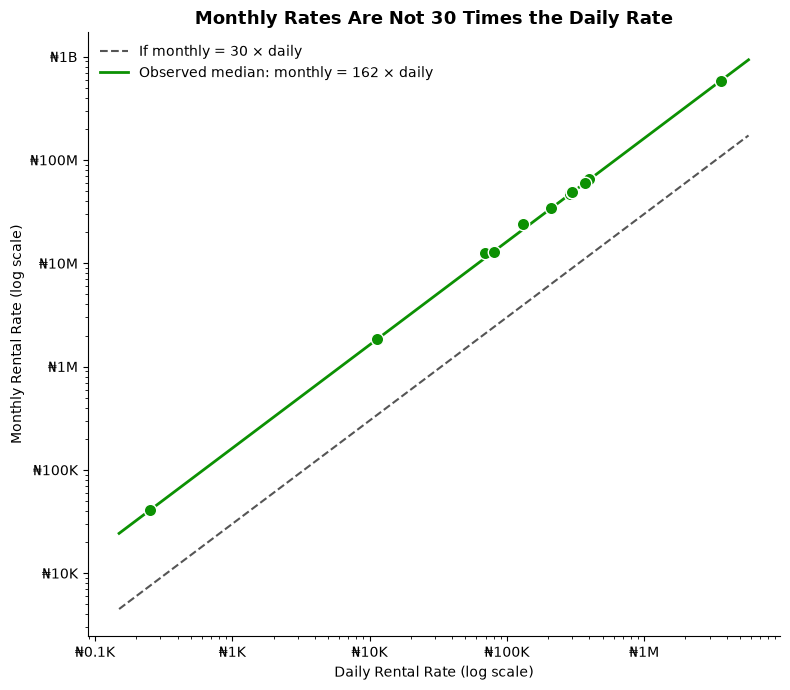

In [35]:
both = df_analysis.dropna(subset=["dailyRate", "monthlyRate"])
ratio = both["monthlyRate"] / both["dailyRate"]
median_ratio = ratio.median()

print("Listings with both rates:", len(both))
print(f"Median monthly-to-daily ratio: {median_ratio:.1f} | min {ratio.min():.1f} | max {ratio.max():.1f}")
print("Listings within 1% of the median ratio:", int(((ratio / median_ratio - 1).abs() < 0.01).sum()))

x_line = np.array([both["dailyRate"].min() * 0.6, both["dailyRate"].max() * 1.6])

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(x_line, x_line * 30, linestyle="--", color=GREY, linewidth=1.5,
        label="If monthly = 30 × daily")
ax.plot(x_line, x_line * median_ratio, color=GREEN, linewidth=2,
        label=f"Observed median: monthly = {median_ratio:.0f} × daily")
ax.scatter(both["dailyRate"], both["monthlyRate"], color=GREEN, s=80,
           edgecolor="white", zorder=3)

def naira(v, pos):
    if v >= 1e9:
        return f"₦{v / 1e9:g}B"
    if v >= 1e6:
        return f"₦{v / 1e6:g}M"
    return f"₦{v / 1e3:g}K"

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(naira))
ax.yaxis.set_major_formatter(FuncFormatter(naira))
ax.set_xlabel("Daily Rental Rate (log scale)")
ax.set_ylabel("Monthly Rental Rate (log scale)")
ax.set_title("Monthly Rates Are Not 30 Times the Daily Rate", fontsize=13, weight="bold")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/03_monthly_vs_daily_rate.png", dpi=200)
plt.show()

**Insight:** Of the 14 listings that show both a daily and a monthly rate, 12 have a monthly rate almost exactly 162 times the daily rate (median ratio 162.0, maximum 182.5). None comes close to the 30 times that a simple 30-day month would give. Such uniform ratios suggest the monthly rates may follow a fixed formula rather than being set independently, which this data cannot confirm. Rental rates should therefore be compared within the same rate type, not converted between daily and monthly. The sample is small, since fewer than 10% of listings show any rental rate.

### Summary Tables and Export

In [36]:

print("Dataset shape:", df_analysis.shape)

print("\nColumns available:")
print(df_analysis.columns.tolist())

print("\nFirst five records:")
display(df_analysis.head())


Dataset shape: (158, 26)

Columns available:
['id', 'title', 'category', 'subcategory', 'location', 'condition', 'availability', 'minimumLease', 'dailyRate', 'monthlyRate', 'annualRate', 'salePrice', 'createdAt', 'updatedAt', 'listingType', 'verificationStatus', 'isFeatured', 'views', 'has_sale_price', 'has_daily_rate', 'has_monthly_rate', 'has_annual_rate', 'location_original', 'location_clean', 'region', 'sale_price_status']

First five records:


,id,title,category,subcategory,location,condition,availability,minimumLease,dailyRate,monthlyRate,...,isFeatured,views,has_sale_price,has_daily_rate,has_monthly_rate,has_annual_rate,location_original,location_clean,region,sale_price_status
0,413,Wuling Bingo Plus,Transport & Logistic,Electric Vehicles,"Lagos, Nigeria",Brand New,Available now,1 Months,69100.0,12600000.0,...,true,26710,True,True,True,True,"Lagos, Nigeria","Lagos, Nigeria",Lagos,Within IQR Range
1,412,Mobile Toilet,Others,Special Requests,"Aboru Iyanapaja, Lagos, Nigeria",Used - Excellent,Available now,,250.0,40500.0,...,false,23269,True,True,True,True,"Aboru Iyanapaja, Lagos, Nigeria","Aboru Iyanapaja, Lagos, Nigeria",Lagos,Within IQR Range
2,411,Scissors lift,Construction & Infrastruture,Excavators,"Lagos, Nigeria",Used - Excellent,Available now,,80000.0,12960000.0,...,false,31551,False,True,True,True,"Lagos, Nigeria","Lagos, Nigeria",Lagos,No Sale Price
3,410,"70, Tones Crane",Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,400000.0,64800000.0,...,false,461,False,True,True,True,"Lagos, Nigeria","Lagos, Nigeria",Lagos,No Sale Price
4,409,Swap buggies,Construction & Infrastruture,Cranes,"Lagos, Nigeria",Used - Excellent,Available now,,290000.0,46980000.0,...,false,311,False,True,True,True,"Lagos, Nigeria","Lagos, Nigeria",Lagos,No Sale Price


In [37]:

# 1. Category summary
category_summary = (
    df_analysis["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Listings")
)
category_summary["Percentage"] = (
    category_summary["Listings"] / len(df_analysis) * 100
).round(2)

# 2. Condition summary
condition_summary = (
    df_analysis["condition"]
    .value_counts(dropna=False)
    .rename_axis("Condition")
    .reset_index(name="Listings")
)
condition_summary["Percentage"] = (
    condition_summary["Listings"] / len(df_analysis) * 100
).round(2)

# 3. Region summary
region_summary = (
    df_analysis["region"]
    .value_counts(dropna=False)
    .rename_axis("Region")
    .reset_index(name="Listings")
)
region_summary["Percentage"] = (
    region_summary["Listings"] / len(df_analysis) * 100
).round(2)

# 4. Sale-price summary
sale_price_summary = df_analysis["salePrice"].describe()

# Display the results
print("CATEGORY DISTRIBUTION")
display(category_summary)

print("CONDITION DISTRIBUTION")
display(condition_summary)

print("REGION DISTRIBUTION")
display(region_summary)

print("SALE-PRICE SUMMARY")
display(sale_price_summary)


CATEGORY DISTRIBUTION


,Category,Listings,Percentage
0,Transport & Logistic,32,20.25
1,Construction & Infrastruture,26,16.46
2,Agriculture & Mining,21,13.29
3,Energy & Power,16,10.13
4,Manufacturing & Industrial,13,8.23
5,Others,12,7.59
6,Telecom & Communication,10,6.33
7,Office & ICT,9,5.70
8,Maritime & Shipping,6,3.80
9,HealthCare & Fitness,5,3.16


CONDITION DISTRIBUTION


,Condition,Listings,Percentage
0,Used - Excellent,78,49.37
1,Brand New,73,46.20
2,Used - Good,7,4.43


REGION DISTRIBUTION


,Region,Listings,Percentage
0,Lagos,84,53.16
1,Abuja / FCT,65,41.14
2,Rivers,3,1.90
3,Oyo,2,1.27
4,Kwara,1,0.63
5,Edo,1,0.63
6,Kaduna,1,0.63
7,Enugu,1,0.63


SALE-PRICE SUMMARY


count              119.0
mean     30242195.369748
std      56557881.502468
min              10000.0
25%             560000.0
50%            6000000.0
75%           42500000.0
max          392450000.0
Name: salePrice, dtype: Float64

In [38]:

export_columns = [
    "title",
    "category",
    "subcategory",
    "location_clean",
    "region",
    "condition",
    "availability",
    "minimumLease",
    "dailyRate",
    "monthlyRate",
    "annualRate",
    "salePrice",
    "createdAt",
    "updatedAt",
    "verificationStatus",
    "isFeatured",
    "has_sale_price",
    "has_daily_rate",
    "has_monthly_rate",
    "has_annual_rate",
    "sale_price_status"
]

df_export = df_analysis[export_columns].copy()

# Give the columns clear, readable names
df_export = df_export.rename(columns={
    "location_clean": "location",
    "minimumLease": "minimum_lease",
    "dailyRate": "daily_rate",
    "monthlyRate": "monthly_rate",
    "annualRate": "annual_rate",
    "salePrice": "sale_price",
    "createdAt": "created_at",
    "updatedAt": "updated_at",
    "verificationStatus": "verification_status",
    "isFeatured": "is_featured"
})

print("Export shape:", df_export.shape)
print("Potential contact fields included:",
      any("contact" in col.lower() for col in df_export.columns))

display(df_export.head())


Export shape: (158, 21)
Potential contact fields included: False


,title,category,subcategory,location,region,condition,availability,minimum_lease,daily_rate,monthly_rate,...,sale_price,created_at,updated_at,verification_status,is_featured,has_sale_price,has_daily_rate,has_monthly_rate,has_annual_rate,sale_price_status
0,Wuling Bingo Plus,Transport & Logistic,Electric Vehicles,"Lagos, Nigeria",Lagos,Brand New,Available now,1 Months,69100.0,12600000.0,...,42000000.0,Mon Jul 06 2026 14:21:33 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:24:31 GMT+0000 (Coordinated...,,true,True,True,True,True,Within IQR Range
1,Mobile Toilet,Others,Special Requests,"Aboru Iyanapaja, Lagos, Nigeria",Lagos,Used - Excellent,Available now,,250.0,40500.0,...,50000.0,Thu Jun 18 2026 09:50:39 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:39:35 GMT+0000 (Coordinated...,,false,True,True,True,True,Within IQR Range
2,Scissors lift,Construction & Infrastruture,Excavators,"Lagos, Nigeria",Lagos,Used - Excellent,Available now,,80000.0,12960000.0,...,<NA>,Mon Jun 15 2026 10:28:44 GMT+0000 (Coordinated...,Sat Oct 17 2026 05:26:25 GMT+0000 (Coordinated...,,false,False,True,True,True,No Sale Price
3,"70, Tones Crane",Construction & Infrastruture,Cranes,"Lagos, Nigeria",Lagos,Used - Excellent,Available now,,400000.0,64800000.0,...,<NA>,Mon Jun 15 2026 10:26:45 GMT+0000 (Coordinated...,Sat Oct 17 2026 02:22:09 GMT+0000 (Coordinated...,,false,False,True,True,True,No Sale Price
4,Swap buggies,Construction & Infrastruture,Cranes,"Lagos, Nigeria",Lagos,Used - Excellent,Available now,,290000.0,46980000.0,...,<NA>,Mon Jun 15 2026 10:24:37 GMT+0000 (Coordinated...,Fri Oct 16 2026 15:02:32 GMT+0000 (Coordinated...,,false,False,True,True,True,No Sale Price


In [39]:

output_file = "data/nigerian_equipment_marketplace_cleaned.csv"

df_export.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Saved file:", output_file)
print("Rows exported:", len(df_export))


Saved file: data/nigerian_equipment_marketplace_cleaned.csv
Rows exported: 158


In [40]:

df_check = pd.read_csv(output_file)

print("Reloaded shape:", df_check.shape)
print("Column names match:", list(df_check.columns) == list(df_export.columns))
print("Contact fields present:",
      any("contact" in col.lower() for col in df_check.columns))

display(df_check.head(3))


Reloaded shape: (158, 21)
Column names match: True
Contact fields present: False


,title,category,subcategory,location,region,condition,availability,minimum_lease,daily_rate,monthly_rate,...,sale_price,created_at,updated_at,verification_status,is_featured,has_sale_price,has_daily_rate,has_monthly_rate,has_annual_rate,sale_price_status
0,Wuling Bingo Plus,Transport & Logistic,Electric Vehicles,"Lagos, Nigeria",Lagos,Brand New,Available now,1 Months,69100.0,12600000.0,...,42000000.0,Mon Jul 06 2026 14:21:33 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:24:31 GMT+0000 (Coordinated...,NaN,True,True,True,True,True,Within IQR Range
1,Mobile Toilet,Others,Special Requests,"Aboru Iyanapaja, Lagos, Nigeria",Lagos,Used - Excellent,Available now,NaN,250.0,40500.0,...,50000.0,Thu Jun 18 2026 09:50:39 GMT+0000 (Coordinated...,Sat Oct 17 2026 04:39:35 GMT+0000 (Coordinated...,NaN,False,True,True,True,True,Within IQR Range
2,Scissors lift,Construction & Infrastruture,Excavators,"Lagos, Nigeria",Lagos,Used - Excellent,Available now,NaN,80000.0,12960000.0,...,NaN,Mon Jun 15 2026 10:28:44 GMT+0000 (Coordinated...,Sat Oct 17 2026 05:26:25 GMT+0000 (Coordinated...,NaN,False,False,True,True,True,No Sale Price


### Project Documentation

In [41]:

project_notes = """
# Nigerian Equipment Marketplace Listing and Price Analysis

## 1. Project Objective
Collect publicly available equipment listings from the Nigerian
Equipment Marketplace and explore their categories, locations,
conditions, and advertised sale and rental prices.

## 2. Data Source
Website: https://equipmentmarket.ng/
Data was retrieved from the website's listings API.

## 3. Data Collection
- Used Python and the requests library to retrieve listing data.
- Retrieved approved listings through paginated API requests.
- Added a 1-second delay between page requests.
- Collected 245 listings across equipment and service types.

## 4. Data Preparation
- Converted the API response into a pandas DataFrame.
- Selected equipment listings, excluding service listings.
- Retained 158 equipment listings for analysis.
- Selected relevant listing, category, location, condition,
  availability, date, and price fields.
- Converted price fields to numeric values where possible.
- Preserved missing prices as missing values rather than zero.
- Added price-availability flags and sale-price status labels.
- Standardized location text and assigned broad regions.
- Checked listing IDs and investigated repeated titles without
  automatically deleting records.

## 5. Privacy and Data Quality
- Seller contact and owner fields were removed at collection, before
  the raw data was saved.
- Excluded contact details from the analysis-ready export.
- Excluded the views field from the export and conclusions because
  the website's view-count behavior may artificially boost values.
- Retained potential sale-price outliers for analysis.
- Recorded missing prices, repeated titles, and rental-price
  patterns as observations rather than confirmed errors.

## 6. Output
Saved a cleaned CSV containing 158 equipment listings and
21 analysis-ready columns.

## 7. Limitations
- The dataset represents listings available at the time of collection.
- Advertised prices are not necessarily completed transaction prices.
- Seller-stated condition and listing details were not independently
  verified.
- Rental prices are available for only a small subset of listings.
- Similar titles do not prove that listings are duplicates.
- Regional groupings are based on text in the supplied locations.
"""

with open("project_documentation.md", "w", encoding="utf-8") as file:
    file.write(project_notes)

print("Project documentation saved.")

Project documentation saved.


In [42]:

with open("project_documentation.md", "r", encoding="utf-8") as file:
    documentation = file.read()

print("Documentation loaded successfully:", len(documentation) > 0)
print("Characters:", len(documentation))
print("\nFirst 500 characters:\n")
print(documentation[:500])


Documentation loaded successfully: True
Characters: 2281

First 500 characters:


# Nigerian Equipment Marketplace Listing and Price Analysis

## 1. Project Objective
Collect publicly available equipment listings from the Nigerian
Equipment Marketplace and explore their categories, locations,
conditions, and advertised sale and rental prices.

## 2. Data Source
Website: https://equipmentmarket.ng/
Data was retrieved from the website's listings API.

## 3. Data Collection
- Used Python and the requests library to retrieve listing data.
- Retrieved approved listings through pa


In [43]:

total_listings = len(df_analysis)

print("KEY FINDINGS")
print("=" * 40)

print(f"Equipment listings analyzed: {total_listings}")

print("\nTOP 5 CATEGORIES")
print(df_analysis["category"].value_counts().head(5).to_string())

print("\nLISTINGS BY REGION")
print(df_analysis["region"].value_counts().to_string())

print("\nCONDITION DISTRIBUTION")
print(df_analysis["condition"].value_counts().to_string())

print("\nSALE PRICE AVAILABILITY")
print(f"Listings with sale prices: {df_analysis['salePrice'].notna().sum()}")
print(f"Listings without sale prices: {df_analysis['salePrice'].isna().sum()}")

print("\nSALE PRICE SUMMARY (LISTINGS WITH PRICES)")
print(df_analysis["salePrice"].describe().round(2).to_string())

print("\nRENTAL PRICE COVERAGE")
for column in ["dailyRate", "monthlyRate", "annualRate"]:
    print(f"{column}: {df_analysis[column].notna().sum()} listings with prices")


KEY FINDINGS
Equipment listings analyzed: 158

TOP 5 CATEGORIES
category
Transport & Logistic            32
Construction & Infrastruture    26
Agriculture & Mining            21
Energy & Power                  16
Manufacturing & Industrial      13

LISTINGS BY REGION
region
Lagos          84
Abuja / FCT    65
Rivers          3
Oyo             2
Kwara           1
Edo             1
Kaduna          1
Enugu           1

CONDITION DISTRIBUTION
condition
Used - Excellent    78
Brand New           73
Used - Good          7

SALE PRICE AVAILABILITY
Listings with sale prices: 119
Listings without sale prices: 39

SALE PRICE SUMMARY (LISTINGS WITH PRICES)
count          119.0
mean     30242195.37
std       56557881.5
min          10000.0
25%         560000.0
50%        6000000.0
75%       42500000.0
max      392450000.0

RENTAL PRICE COVERAGE
dailyRate: 15 listings with prices
monthlyRate: 14 listings with prices
annualRate: 14 listings with prices


In [44]:
findings = """

## 8. Key Findings

### Listing Categories
Transport & Logistic was the largest category, with 32 listings (20.25%).
Construction & Infrastruture followed with 26 (16.46%), and
Agriculture & Mining had 21 (13.29%). Together, these three categories
accounted for 50% of the 158 equipment listings.

### Geographic Distribution
Lagos accounted for 84 listings (53.16%), while Abuja / FCT accounted
for 65 (41.14%). Together, these regions represented 94.30% of the
sample. This describes the collected listings and does not establish
market demand or total equipment availability in Nigeria.

### Equipment Condition
There were 78 listings marked Used - Excellent (49.37%), 73 marked
Brand New (46.20%), and 7 marked Used - Good (4.43%). These conditions
were reported in the listings and were not independently verified.

### Sale Prices
Of 158 listings, 119 had an advertised sale price and 39 did not.
Among listings with prices, the median was NGN 6,000,000 and the mean
was approximately NGN 30,242,195. The mean being substantially higher
than the median suggests that high-priced listings influence the
average. The observed price range was NGN 10,000 to NGN 392,450,000.

Six sale prices were flagged as potential outliers (above
NGN 105,410,000) using the interquartile-range method. They were
retained because unusual prices are not automatically errors.

### Rental Prices
Daily rates were available for 15 listings, while monthly and annual
rates were each available for 14 listings. This limited coverage
restricts the conclusions that can be drawn about rental pricing.

### Data Quality
The verification status field was blank for all 158 listings, and the
minimum lease field was blank for 88.0%, so neither can support
analysis. Only 4 listings (2.5%) lacked a subcategory. A total of 29
listings (18.4%) showed no price in any of the four price fields.

### Rental Rate Pattern
Of the 14 listings showing both a daily and a monthly rate, 12 had a
monthly rate almost exactly 162 times the daily rate (median ratio
162.0, maximum 182.5), not the 30 times a simple 30-day month would
give. This suggests the monthly rates may follow a fixed formula,
which this data cannot confirm. Rental rates should be compared within
the same rate type, not converted between daily and monthly.

### Interpretation
The analysis summarizes advertised equipment listings collected at
the time of scraping. It does not measure completed transactions,
market demand, or the full Nigerian equipment market.
"""

with open("project_documentation.md", "a", encoding="utf-8") as file:
    file.write(findings)

print("Key findings appended to project documentation.")

Key findings appended to project documentation.
